# 03 — Explicabilité et audit d'équité

**Objectif :** répondre à deux questions du jury et du cahier des charges.
1. **Pourquoi** le modèle juge-t-il un joueur suspect ? (critère 1.5, exigence F3)
2. Le modèle soupçonne-t-il à tort **certains groupes** plus que d'autres ? (critères 1.1 et 5.5)

Méthode d'explication : **SHAP**. Pour chaque prédiction, SHAP répartit l'écart entre le score du joueur et le score moyen entre les variables. Contribution positive → pousse vers « tricheur » ; négative → vers « honnête ».

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Permet d'importer le code du dossier src/ depuis le dossier notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.viz import BLUE, GRAY, ORANGE, apply_style

apply_style()
pd.set_option("display.precision", 3)

In [2]:
from src.config import FEATURES
from src.data.generate import generate_dataset
from src.explain import FEATURE_LABELS, compute_contributions, explain
from src.train import split_by_player, train_and_select

df = generate_dataset(n_matches=50_000, seed=42)
result = train_and_select(df, seed=42)
_, _, test = split_by_player(df, seed=42)
test_scores = result.model.predict_proba(test[FEATURES])[:, 1]
print("Modèle :", result.model_name)

Modèle : gradient_boosting


## 1. Explicabilité globale : quelles variables comptent le plus ?

/Users/emma/soutenance-aia/bloc4-ia-deploiement/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


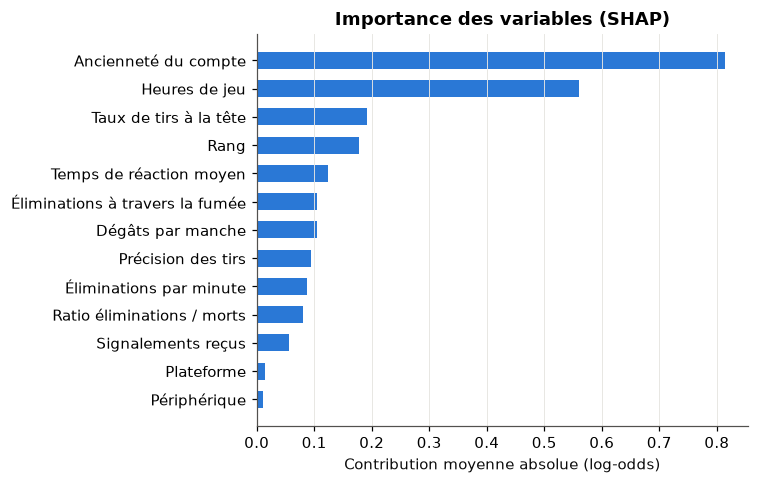

In [3]:
sample = test.sample(2_000, random_state=42)
background = result.explain_info.get("background_mean")
contributions = compute_contributions(result.model, sample, background)
importance = contributions.abs().mean().sort_values()
importance.index = [FEATURE_LABELS[f][0] for f in importance.index]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.set_xlabel("Contribution moyenne absolue (log-odds)")
ax.set_title("Importance des variables (SHAP)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Lecture :** les variables les plus utilisées sont celles qui trahissent un aimbot (tirs à la tête, temps de réaction) ou un wallhack (éliminations à travers la fumée), complétées par le contexte (rang, ancienneté du compte).
Point de vigilance : vérifier que les signalements ne dominent pas, sinon le modèle reproduirait le biais de la règle actuelle.

## 2. Explicabilité locale : la fiche d'un joueur suspect

In [4]:
most_suspect = test.iloc[np.argsort(-test_scores)[:3]]
all_reasons = explain(result.model, most_suspect, result.explain_info)
for (_, row), reasons in zip(most_suspect.iterrows(), all_reasons):
    score = result.model.predict_proba(row[FEATURES].to_frame().T)[0, 1]
    print(f"Joueur {row['player_id'][:8]}… | rang {row['rank_tier']} | probabilité {score:.0%}")
    for reason in reasons:
        print("   •", reason["text"])
    print()

Joueur 8274bbcc… | rang 6 | probabilité 99%
   • Éliminations à travers la fumée : 23 % (joueurs honnêtes de son rang : 2 %) — augmente le risque
   • Heures de jeu : 29 h (joueurs honnêtes de son rang : 238 h) — augmente le risque
   • Ancienneté du compte : 22 jours (joueurs honnêtes de son rang : 282 jours) — augmente le risque

Joueur 8274bbcc… | rang 6 | probabilité 99%
   • Éliminations à travers la fumée : 20 % (joueurs honnêtes de son rang : 2 %) — augmente le risque
   • Heures de jeu : 29 h (joueurs honnêtes de son rang : 238 h) — augmente le risque
   • Ancienneté du compte : 22 jours (joueurs honnêtes de son rang : 282 jours) — augmente le risque

Joueur 8274bbcc… | rang 6 | probabilité 99%
   • Éliminations à travers la fumée : 16 % (joueurs honnêtes de son rang : 2 %) — augmente le risque
   • Heures de jeu : 29 h (joueurs honnêtes de son rang : 238 h) — augmente le risque
   • Ancienneté du compte : 22 jours (joueurs honnêtes de son rang : 282 jours) — augmente le risque

C'est exactement ce que le modérateur verra dans la console : 3 raisons en français, chacune comparée aux **joueurs honnêtes du même rang**. Il peut ainsi vérifier le raisonnement du modèle avant toute décision, et le joueur peut recevoir une explication en cas de contestation.

## 3. Audit d'équité

In [5]:
rows = []
for group, report in result.fairness.items():
    for value, rates in report["rates"].items():
        rows.append({"groupe": group, "valeur": value, **rates})
fairness_table = pd.DataFrame(rows)
fairness_table

,groupe,valeur,n_honest,n_cheaters,false_positive_rate,recall,reliable
0,input_device,clavier_souris,6423,175,0.015,0.549,True
1,input_device,manette,3280,119,0.009,0.597,True
2,platform,console,2781,99,0.009,0.576,True
3,platform,pc,6922,195,0.015,0.564,True
4,accessibility_mode,False,9299,280,0.013,0.571,True
5,accessibility_mode,True,404,14,0.010,0.500,True
6,age_band,16-17,778,46,0.008,0.500,True
7,age_band,18-24,4647,153,0.014,0.569,True
8,age_band,25-34,2769,67,0.015,0.657,True
9,age_band,35+,1509,28,0.008,0.464,True


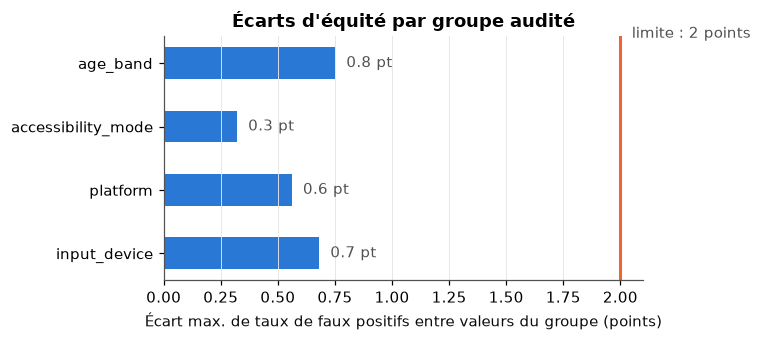

In [6]:
gaps = pd.Series({g: r["fpr_gap"] for g, r in result.fairness.items()})
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(gaps.index, gaps.values * 100, color=BLUE, height=0.5)
ax.axvline(2, color=ORANGE, linewidth=2)
ax.text(2.05, len(gaps) - 0.6, "limite : 2 points", color=GRAY)
for y, value in enumerate(gaps.values * 100):
    ax.text(value + 0.05, y, f"{value:.1f} pt", va="center", color=GRAY)
ax.set_xlabel("Écart max. de taux de faux positifs entre valeurs du groupe (points)")
ax.set_title("Écarts d'équité par groupe audité")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Lecture :**
- Tous les écarts de taux de faux positifs sont **sous la limite de 2 points** du cahier des charges.
- **Manette :** le taux de faux positifs n'est pas plus élevé à la manette, malgré une précision naturellement supérieure. Le modèle a appris, grâce à la variable `input_device`, qu'une forte précision est normale à la manette.
- **Accessibilité :** pas de sur-signalement des joueurs utilisant l'option d'accessibilité.
- **Limite :** certains groupes sont petits (ex. 16-17 ans, mode accessibilité : quelques centaines de joueurs honnêtes dans le test) ; leurs taux sont donc moins précis. Les groupes de moins de 100 honnêtes sont exclus du calcul d'écart et signalés.

Les variables d'audit (`age_band`, `accessibility_mode`) ne sont **jamais utilisées par le modèle** et ne sont analysées que de façon **agrégée** (cahier des charges, section 8).

## Conclusions
- Chaque prédiction est accompagnée de 3 raisons compréhensibles par un non-spécialiste.
- Le modèle respecte les seuils d'équité ; l'audit est recalculé à chaque réentraînement, et un modèle inéquitable n'est jamais promu en production.